# 06 · Where coverage fails: coverage by RUL stratum (all subsets, 10 seeds)

**Question (H1).** A 90 % interval covers about 90 % of the rows *on average*. Does it cover 90 % near failure, where the maintenance decision is taken?

**Data.** `results/crossfit_coverage.csv`, written by
`python -m src.run crossfit --subsets FD001 FD002 FD003 FD004 --seeds 0-9` (engine-level 5-fold cross-fitting: every run-to-failure engine is evaluated once, by models that never saw it; calibration uses a separate fold).

**Methods.** SCP = split conformal, one width for everyone. Mondrian = split conformal calibrated separately in bins of the *predicted* RUL (what is known when deciding). CQR = conformalized quantile regression (LightGBM quantile models, adaptive width).

**Two views.** By *predicted* RUL: what Mondrian is calibrated on. By *true* RUL: what drives failures (an engine fails when the lower bound is above the truth at the moment the true RUL equals the notice horizon). Coverage is reported per stratum with the miss *direction*: `below` = truth under the lower bound = an alert that comes too late.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import summarize as S
from src.config import CONFIDENCE_LEVEL, PLANNED_REMOVAL_EUR
from src.plots import save

pd.set_option("display.width", 180)
pd.set_option("display.precision", 3)
R = S.load()
{k: len(v) for k, v in R.items()}

{'accuracy': 80, 'coverage': 2200, 'decisions': 13680, 'curves': 46240}

## Point accuracy (context only: RMSE is not the outcome of this thesis)

In [2]:
acc = R["accuracy"]
acc.groupby(["subset", "model"])[["rmse_all", "rmse_near_failure", "rmse_far"]].median().round(2)

rmse_all  rmse_near_failure  rmse_far
subset model                                        
FD001  lgbm       19.35              18.04     19.77
       linear     21.49              22.68     21.14
FD002  lgbm       19.16              18.42     19.36
       linear     20.82              21.98     20.45
FD003  lgbm       17.96              15.65     18.53
       linear     19.43              22.75     18.46
FD004  lgbm       17.89              17.36     18.02
       linear     19.79              22.95     18.87

## Coverage by predicted-RUL stratum (LightGBM, mean over seeds)

In [3]:
cov = R["coverage"]
for subset in sorted(cov["subset"].unique()):
    print(subset)
    display(S.coverage_table(cov, by="pred", subset=subset).round(3))

FD001


,<= 25,25-50,50-75,75-100,> 100
method,,,,,
CQR,0.918,0.858,0.811,0.806,0.927
Mondrian,0.897,0.890,0.884,0.891,0.895
SCP,1.000,0.964,0.831,0.730,0.918


FD002


,<= 25,25-50,50-75,75-100,> 100
method,,,,,
CQR,0.919,0.870,0.831,0.846,0.921
Mondrian,0.897,0.892,0.889,0.895,0.899
SCP,0.997,0.972,0.824,0.734,0.923


FD003


,<= 25,25-50,50-75,75-100,> 100
method,,,,,
CQR,0.926,0.856,0.763,0.768,0.930
Mondrian,0.887,0.877,0.879,0.885,0.899
SCP,0.998,0.945,0.768,0.676,0.937


FD004


,<= 25,25-50,50-75,75-100,> 100
method,,,,,
CQR,0.932,0.884,0.844,0.807,0.920
Mondrian,0.899,0.891,0.888,0.895,0.901
SCP,0.979,0.944,0.812,0.679,0.934


## Coverage by TRUE-RUL stratum: the view that decides failures

In [4]:
for subset in sorted(cov["subset"].unique()):
    print(subset)
    display(S.coverage_table(cov, by="true", subset=subset).round(3))

FD001


,<= 25,25-50,50-75,75-100,100-125,> 125
method,,,,,,
CQR,0.906,0.813,0.804,0.873,0.881,0.939
Mondrian,0.930,0.818,0.718,0.809,0.947,0.968
SCP,0.991,0.836,0.732,0.867,0.904,0.940


FD002


,<= 25,25-50,50-75,75-100,100-125,> 125
method,,,,,,
CQR,0.909,0.830,0.837,0.883,0.918,0.926
Mondrian,0.937,0.817,0.705,0.821,0.950,0.974
SCP,0.990,0.824,0.714,0.887,0.908,0.949


FD003


,<= 25,25-50,50-75,75-100,100-125,> 125
method,,,,,,
CQR,0.923,0.823,0.786,0.807,0.849,0.939
Mondrian,0.939,0.849,0.729,0.686,0.926,0.960
SCP,0.993,0.866,0.731,0.790,0.862,0.944


FD004


,<= 25,25-50,50-75,75-100,100-125,> 125
method,,,,,,
CQR,0.934,0.854,0.820,0.838,0.888,0.931
Mondrian,0.941,0.854,0.698,0.696,0.944,0.972
SCP,0.989,0.843,0.681,0.813,0.892,0.955


## Miss direction near failure (true RUL ≤ 25 and 25–50): share of rows with the truth BELOW the lower bound

In [5]:
near = cov[(cov["by"] == "true") & (cov["model"] == "lgbm") & (cov["stratum"] <= 1)]
near.pivot_table(index=["subset", "method"], columns="label", values="below", aggfunc="mean").round(3)

label            25-50  <= 25
subset method                
FD001  CQR       0.150  0.072
       Mondrian  0.130  0.051
       SCP       0.164  0.009
FD002  CQR       0.137  0.080
       Mondrian  0.130  0.044
       SCP       0.176  0.010
FD003  CQR       0.143  0.070
       Mondrian  0.087  0.041
       SCP       0.134  0.007
FD004  CQR       0.124  0.063
       Mondrian  0.108  0.050
       SCP       0.156  0.011

## Interval width per stratum (the price of each method)

In [6]:
S.coverage_table(cov, by="pred", value="mean_width").round(1)

,<= 25,25-50,50-75,75-100,> 100
method,,,,,
CQR,23.1,43.2,62.9,70.5,39.2
Mondrian,18.5,47.0,82.2,76.4,34.4
SCP,44.6,63.2,64.5,62.6,40.2


## Figure

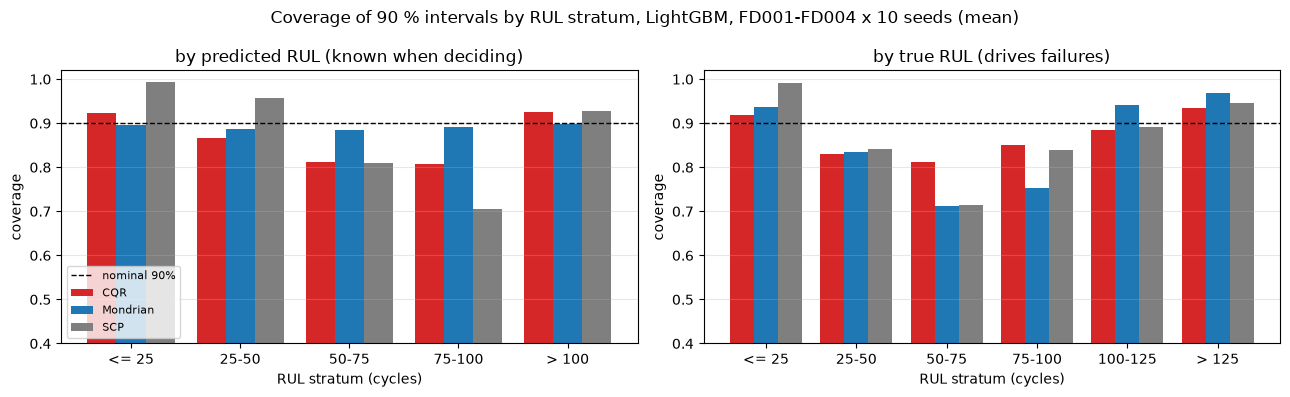

In [7]:
tables = {"by predicted RUL (known when deciding)": S.coverage_table(cov, by="pred"),
          "by true RUL (drives failures)": S.coverage_table(cov, by="true")}
from src.plots import plot_coverage_by_stratum
fig = plot_coverage_by_stratum(
    tables, CONFIDENCE_LEVEL, "Coverage of 90 % intervals by RUL stratum, LightGBM, FD001-FD004 x 10 seeds (mean)")
save(fig, "crossfit_coverage_by_stratum.png")

## Reading (FD001-FD004, 10 seeds, LightGBM, 90 % intervals)

* **Marginal coverage hides the pattern (H1).** By predicted RUL, split conformal covers 0.99 near failure (≤ 25) but 0.70 at 75-100. CQR covers 0.92 near failure and about 0.81 in mid-life.
* **Mondrian calibration fixes what it targets (H2).** 0.88-0.90 in every predicted-RUL stage, with intervals of 19 cycles near failure instead of 45 for split conformal.
* **It does not fix what causes failures.** By *true* RUL, every method misses on the late side (truth below the lower bound) 11-16 % of the time at 25-50 cycles and 14-27 % at 50-75, against a nominal 5 %. Engines that degrade faster than predicted look healthy to every calibration that only sees the prediction. These misses become failures when the shop needs about 30 cycles of notice (notebook 07).
* Exact conditional coverage is impossible without assumptions (Barber et al. 2019). Wording for the thesis: "intervals calibrated to a nominal 90 % marginal coverage, verified empirically; coverage within predicted-RUL stages by Mondrian calibration".